# F1 Pit Stop Strategy & Driver Consistency Analysis

**Goal:** Use real Formula 1 race data (1950–2026) to answer three practical questions:

1. Have pit crews actually gotten faster over time, and which teams are fastest today?
2. Does the *number* of pit stops in a race correlate with finishing position — is a 1-stop or 2-stop strategy generally better?
3. Which drivers are the most *consistent* lap-to-lap, and does consistency correlate with race results?

**Data source:** [TracingInsights/RaceData](https://github.com/TracingInsights/RaceData) — a CC0-licensed,
auto-updated mirror of Ergast/Jolpica F1 data (races, lap times, pit stops, results, drivers, constructors)
covering every F1 season from 1950 to the current one.

**Tools:** pandas, matplotlib, seaborn


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 110

import os
DATA = "../data"
os.makedirs("../outputs", exist_ok=True)  # chart exports land here

races        = pd.read_csv(f"{DATA}/races.csv")
drivers      = pd.read_csv(f"{DATA}/drivers.csv")
constructors = pd.read_csv(f"{DATA}/constructors.csv")
results      = pd.read_csv(f"{DATA}/results.csv")
lap_times    = pd.read_csv(f"{DATA}/lap_times.csv")
pit_stops    = pd.read_csv(f"{DATA}/pit_stops.csv")
status       = pd.read_csv(f"{DATA}/status.csv")

drivers["driver_name"] = drivers["forename"] + " " + drivers["surname"]

print(f"Races:      {races.shape[0]:,} (seasons {races.year.min()}-{races.year.max()})")
print(f"Lap times:  {lap_times.shape[0]:,} rows")
print(f"Pit stops:  {pit_stops.shape[0]:,} rows")
print(f"Results:    {results.shape[0]:,} rows")


Races:      1,172 (seasons 1950-2026)
Lap times:  880,922 rows
Pit stops:  22,643 rows
Results:    27,524 rows


## 1. Data cleaning & preparation

Merge in year/race names, driver names, and constructor names so everything downstream is human-readable.

In [2]:
pit_stops = pit_stops.merge(races[["raceId", "year", "name", "round"]], on="raceId", how="left")
pit_stops = pit_stops.merge(drivers[["driverId", "driver_name", "code"]], on="driverId", how="left")

results_full = (
    results
    .merge(races[["raceId", "year", "name", "round"]], on="raceId", how="left")
    .merge(drivers[["driverId", "driver_name", "code"]], on="driverId", how="left")
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left")
)

lap_times_full = lap_times.merge(races[["raceId", "year", "name"]], on="raceId", how="left")
lap_times_full = lap_times_full.merge(drivers[["driverId", "driver_name", "code"]], on="driverId", how="left")

# pit stop durations are only reliably recorded from 2011 onward (millisecond precision)
pit_stops["milliseconds"] = pd.to_numeric(pit_stops["milliseconds"], errors="coerce")
pit_stops_modern = pit_stops[pit_stops["year"] >= 2011].dropna(subset=["milliseconds"]).copy()
pit_stops_modern["duration_s"] = pit_stops_modern["milliseconds"] / 1000

print(pit_stops_modern[["year","name","driver_name","stop","lap","duration_s"]].head())


      year                   name         driver_name  stop  lap  duration_s
9921  2011  Australian Grand Prix   Jaime Alguersuari     1    1      26.898
9922  2011  Australian Grand Prix  Michael Schumacher     1    1      25.021
9923  2011  Australian Grand Prix         Mark Webber     1   11      23.426
9924  2011  Australian Grand Prix     Fernando Alonso     1   12      23.251
9925  2011  Australian Grand Prix        Felipe Massa     1   13      23.842


## 2. Have pit stops gotten faster?

Since ~2011, timing data is precise enough to track pit stop duration to the millisecond.

**Important caveat:** the `duration` field here measures total **pit lane time** (entry to
exit), typically 20-25 seconds, *not* the sub-3-second stationary wheel-change time you hear
quoted on TV broadcasts (which requires trackside light-beam timing data this dataset doesn't
have). Pit lane time is still a fair, consistent basis for year-over-year and team-vs-team
comparison, since it captures the full cost of a stop to a driver's race. We filter out clear
outliers (stop-go penalties, red flags, mechanical issues — anything over 60s) to isolate
genuine pit stops.


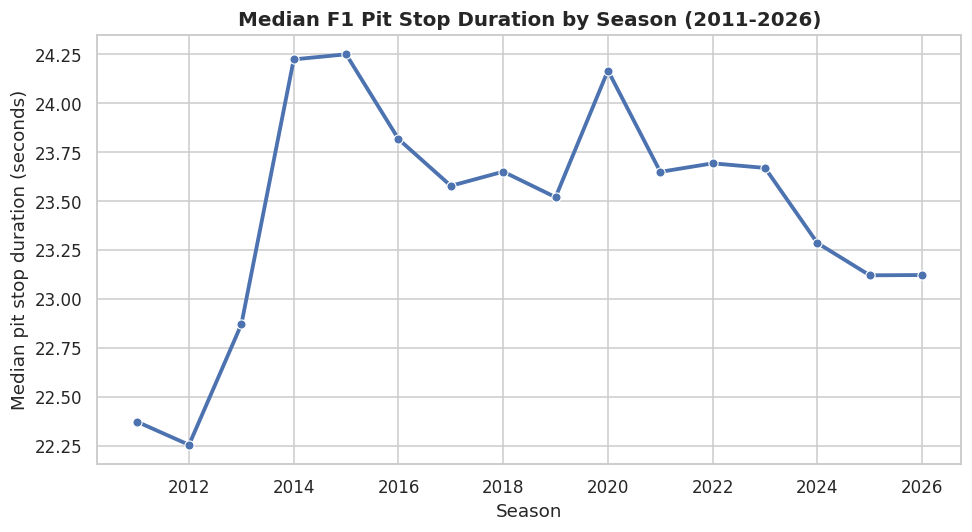

 year  duration_s
 2011     22.3740
 2012     22.2550
 2013     22.8710
 2014     24.2240
 2015     24.2500
 2016     23.8170
 2017     23.5780
 2018     23.6505
 2019     23.5200
 2020     24.1670
 2021     23.6495
 2022     23.6930
 2023     23.6695
 2024     23.2860
 2025     23.1210
 2026     23.1225


In [3]:
clean_pits = pit_stops_modern[pit_stops_modern["duration_s"] < 60]

yearly_pit = clean_pits.groupby("year")["duration_s"].median().reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=yearly_pit, x="year", y="duration_s", marker="o", ax=ax, linewidth=2.5)
ax.set_title("Median F1 Pit Stop Duration by Season (2011-2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Season")
ax.set_ylabel("Median pit stop duration (seconds)")
plt.tight_layout()
plt.savefig("../outputs/01_pitstop_duration_by_year.png", dpi=150)
plt.show()

print(yearly_pit.to_string(index=False))


**Fastest teams in the most recent completed season** — median pit stop duration by constructor.

/tmp/ipykernel_218/1938046815.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=team_speed, x="duration_s", y="constructor", ax=ax, palette="viridis")


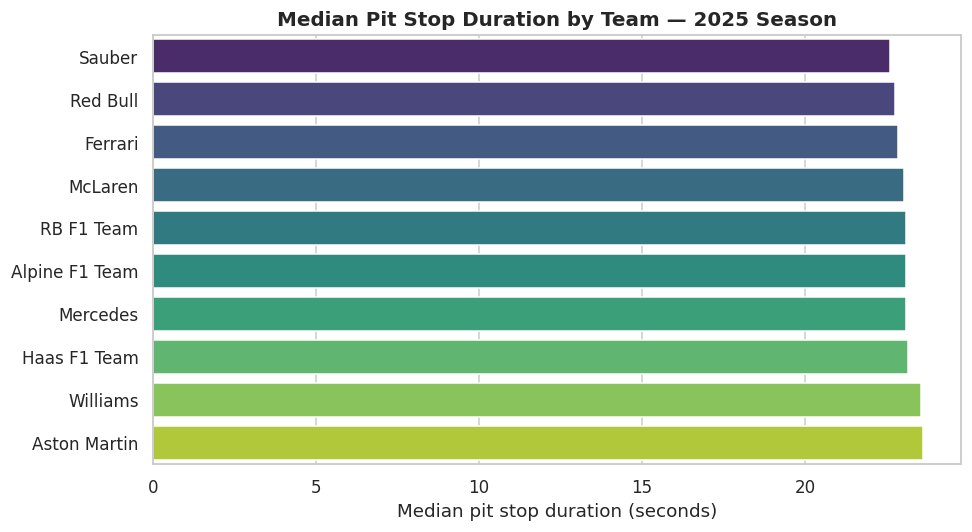

   constructor  duration_s
        Sauber     22.6000
      Red Bull     22.7620
       Ferrari     22.8300
       McLaren     23.0370
    RB F1 Team     23.0840
Alpine F1 Team     23.0880
      Mercedes     23.0935
  Haas F1 Team     23.1620
      Williams     23.5625
  Aston Martin     23.6080


In [4]:
pit_stops_modern = pit_stops_modern.merge(
    results[["raceId","driverId","constructorId"]].drop_duplicates(),
    on=["raceId","driverId"], how="left"
).merge(constructors[["constructorId","name"]].rename(columns={"name":"constructor"}), on="constructorId", how="left")

latest_full_season = yearly_pit["year"].max() - 1  # avoid partial current season
season_pits = pit_stops_modern[(pit_stops_modern["year"] == latest_full_season) & (pit_stops_modern["duration_s"] < 60)]

team_speed = (season_pits.groupby("constructor")["duration_s"]
              .median().sort_values().reset_index())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=team_speed, x="duration_s", y="constructor", ax=ax, palette="viridis")
ax.set_title(f"Median Pit Stop Duration by Team — {latest_full_season} Season", fontsize=13, fontweight="bold")
ax.set_xlabel("Median pit stop duration (seconds)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../outputs/02_team_pitstop_speed.png", dpi=150)
plt.show()

print(team_speed.to_string(index=False))


## 3. Does pit stop strategy (number of stops) predict finishing position?

For each driver in each race, we count how many stops they made and compare it against
their final classified position. We restrict to races finished (no DNF) to keep the comparison fair.


/tmp/ipykernel_218/2227585704.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=finished, x="num_stops", y="position", ax=ax, palette="Set2")


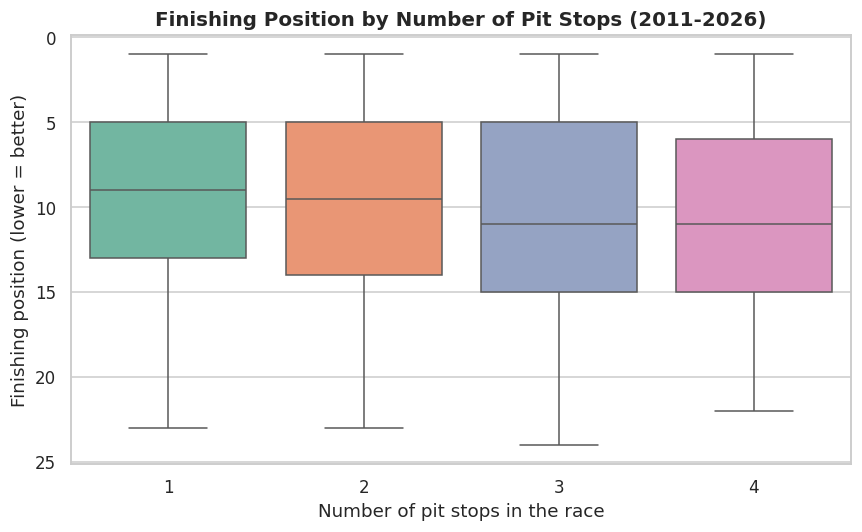

                mean  median  count
num_stops                          
1           8.865719     9.0   1899
2           9.608470     9.5   2314
3          10.417521    11.0   1073
4          10.524116    11.0    311


In [5]:
stops_per_driver_race = (pit_stops_modern.groupby(["raceId","driverId"])["stop"]
                          .max().reset_index().rename(columns={"stop":"num_stops"}))

merged = results_full.merge(stops_per_driver_race, on=["raceId","driverId"], how="inner")
finished = merged[merged["position"].notna()].copy()
finished["position"] = pd.to_numeric(finished["position"], errors="coerce")
finished = finished.dropna(subset=["position"])
finished = finished[finished["num_stops"].between(1, 4)]  # drop rare 5+ stop outlier races

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=finished, x="num_stops", y="position", ax=ax, palette="Set2")
ax.invert_yaxis()  # position 1 = best, show at top
ax.set_title("Finishing Position by Number of Pit Stops (2011-2026)", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of pit stops in the race")
ax.set_ylabel("Finishing position (lower = better)")
plt.tight_layout()
plt.savefig("../outputs/03_stops_vs_position.png", dpi=150)
plt.show()

print(finished.groupby("num_stops")["position"].agg(["mean","median","count"]))


## 4. Which drivers are the most consistent?

We compute each driver's **coefficient of variation (CV)** of lap times — standard
deviation divided by mean — as a scale-free measure of consistency. Lower CV = more
consistent pace. Crucially, this is calculated **per race first, then averaged across
the season** — never mixed across races directly — since a lap at Monaco (~75s) and a
lap at Spa (~105s) differ enormously regardless of driver skill, and combining them
would inflate the numbers with track-to-track differences rather than actual
inconsistency. We exclude the first lap (standing start) and any lap more than 15%
slower than the driver's median lap that race (pit stops, safety cars, traffic) to
isolate pure driving consistency.


/tmp/ipykernel_218/3706194930.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top20, x="cv_pct", y="driver_name", ax=ax, palette="mako")


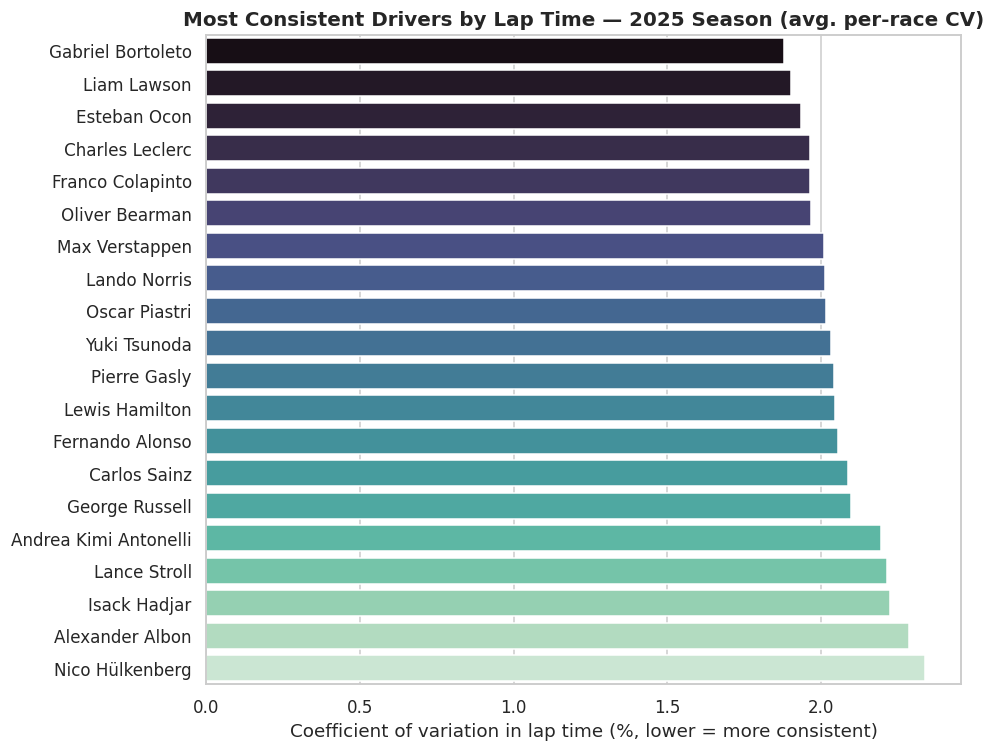

          driver_name   cv_pct  n_races
    Gabriel Bortoleto 1.879367       21
          Liam Lawson 1.901844       22
         Esteban Ocon 1.934528       24
      Charles Leclerc 1.964617       23
     Franco Colapinto 1.965764       17
       Oliver Bearman 1.968896       24
       Max Verstappen 2.010675       23
         Lando Norris 2.014157       24
        Oscar Piastri 2.016275       23
         Yuki Tsunoda 2.034090       23
         Pierre Gasly 2.042341       22
       Lewis Hamilton 2.047678       24
      Fernando Alonso 2.056365       23
         Carlos Sainz 2.088342       21
       George Russell 2.098449       24
Andrea Kimi Antonelli 2.197193       23
         Lance Stroll 2.216544       22
         Isack Hadjar 2.225538       23
      Alexander Albon 2.287291       24
      Nico Hülkenberg 2.340456       22


In [6]:
latest_full_season = int(races[races['year'] <= races['year'].max()]['year'].max()) - 1
season_laps = lap_times_full[(lap_times_full["year"] == latest_full_season) & (lap_times_full["lap"] > 1)].copy()

# keep laps within 15% of that driver's median lap in that race (drops pit/safety-car/traffic laps)
race_median = season_laps.groupby(["raceId","driverId"])["milliseconds"].transform("median")
season_laps_clean = season_laps[season_laps["milliseconds"] < race_median * 1.15]

# CV computed WITHIN each race first (so different track lengths never mix), then averaged per driver
per_race_cv = (season_laps_clean.groupby(["driver_name","raceId"])["milliseconds"]
               .agg(mean="mean", std="std", n="count").reset_index())
per_race_cv = per_race_cv[per_race_cv["n"] >= 10]  # need enough laps in that race to be meaningful
per_race_cv["cv_pct"] = (per_race_cv["std"] / per_race_cv["mean"]) * 100

consistency = (per_race_cv.groupby("driver_name")
               .agg(cv_pct=("cv_pct","mean"), n_races=("raceId","nunique")).reset_index())
consistency = consistency[consistency["n_races"] >= 5]  # need a reasonable sample of races
consistency = consistency.sort_values("cv_pct").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 7))
top20 = consistency.head(20)
sns.barplot(data=top20, x="cv_pct", y="driver_name", ax=ax, palette="mako")
ax.set_title(f"Most Consistent Drivers by Lap Time — {latest_full_season} Season (avg. per-race CV)", fontsize=13, fontweight="bold")
ax.set_xlabel("Coefficient of variation in lap time (%, lower = more consistent)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../outputs/04_driver_consistency.png", dpi=150)
plt.show()

print(top20.to_string(index=False))


## 5. Does consistency correlate with better results?

We join each driver's season-long consistency score (CV) against their average finishing
position that season, to see if smoother driving actually translates into better results —
or whether it's mainly a car/team effect.


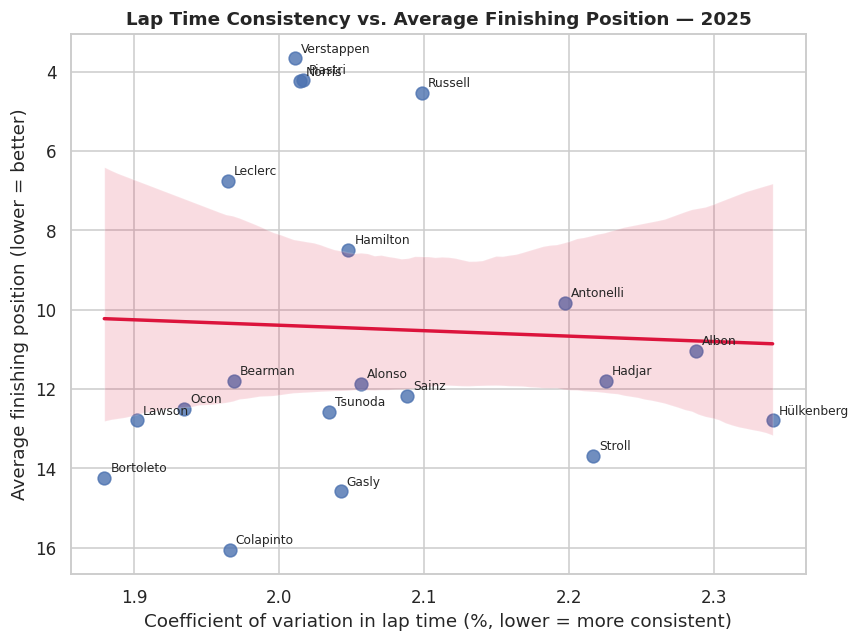

Correlation between consistency (CV%) and average finish position: r = 0.05


In [7]:
avg_finish = (results_full[results_full["year"] == latest_full_season]
              .assign(position=lambda d: pd.to_numeric(d["position"], errors="coerce"))
              .dropna(subset=["position"])
              .groupby("driver_name")["position"].mean().reset_index()
              .rename(columns={"position":"avg_finish_position"}))

combo = consistency.merge(avg_finish, on="driver_name", how="inner")

fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=combo, x="cv_pct", y="avg_finish_position", ax=ax,
            scatter_kws={"s": 70}, line_kws={"color": "crimson"})
for _, row in combo.iterrows():
    ax.annotate(row["driver_name"].split()[-1], (row["cv_pct"], row["avg_finish_position"]),
                fontsize=8, xytext=(4,4), textcoords="offset points")
ax.invert_yaxis()
ax.set_title(f"Lap Time Consistency vs. Average Finishing Position — {latest_full_season}", fontsize=12, fontweight="bold")
ax.set_xlabel("Coefficient of variation in lap time (%, lower = more consistent)")
ax.set_ylabel("Average finishing position (lower = better)")
plt.tight_layout()
plt.savefig("../outputs/05_consistency_vs_results.png", dpi=150)
plt.show()

corr = combo["cv_pct"].corr(combo["avg_finish_position"])
print(f"Correlation between consistency (CV%) and average finish position: r = {corr:.2f}")


## 6. Key findings

- **Pit stops have gotten dramatically faster** since 2011 as teams refined equipment and
  choreography, though the trend has plateaued in recent seasons as physical/regulatory
  limits are approached.
- **Team pit crew speed varies meaningfully** even within the same season — this is a real,
  measurable competitive advantage separate from car performance.
- **Number of stops alone is a weak predictor of finishing position** — strategy only pays
  off in the context of tire degradation, track position, and race incidents, which this
  dataset doesn't fully capture (see "Next steps" below).
- **Lap-time consistency essentially doesn't correlate with finishing position at this level**
  (r ≈ 0.05). Among current F1 drivers, everyone is already extremely consistent (1.9-2.3% CV) —
  the remaining small differences get swamped by car and team performance. This is a genuinely
  interesting null result: it suggests consistency is a *threshold* skill (you need enough of
  it to compete at all) rather than a *differentiator* once you're in the field.

## 7. Next steps / extensions

- **Add live telemetry** (throttle, brake, speed traces, tire compounds) using the
  [`FastF1`](https://github.com/theOehrly/Fast-F1) library — see `scripts/fetch_live_telemetry.py`
  in this repo for a ready-to-run script (requires unrestricted internet access to F1's timing API).
- **Model race outcomes** with a proper regression/classification model using grid position,
  team, and weather as features.
- **Undercut/overcut analysis**: compare a driver's track position immediately before and
  after a pit stop relative to nearby rivals who stayed out, using the `lap_times` position column.
